In [8]:
import torch
from torch.utils.data import DataLoader

from deep_models.vae import SparseConvVAE, plot_sparse_latent_usage
from deep_models.vae_train import *
from deep_models.data import load_folds, make_splits, S00MILDataset

In [9]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 7

In [10]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
device = torch.device("cuda")

train=1085  val=132  test=136


In [11]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True, return_cond=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False, return_cond=True)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

In [12]:
model = SparseConvVAE(latent=64,
                      alpha=0.1,          
                      cond_dim=2,         
                      cond_in_encoder=True).to(device)
state_dict = torch.load(f"best_scvae_fold{split_k}.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

SparseConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=66, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=66, out_features=64, bias=True)
  (fc): Linear(in_features=66, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
  (fc_gamma): Linear(in_features=66, out_features=64, bias=True)
)

In [13]:
val_z, val_gamma, val_y = encode_bags_sparse(model, val_loader, device)

used units: 31/64   mean L0 per window: 30.8


(<Figure size 1400x400 with 3 Axes>,
 array([ 3,  7, 11,  8, 21, 23, 18, 19, 28, 29, 30, 47, 40, 38, 61, 59, 48,
        50, 51, 52, 55, 53, 57, 56, 62, 41, 42, 32, 37,  0, 16, 43, 15, 25,
        31, 27, 24, 17, 20, 22,  6,  5,  4,  9, 10, 12, 13, 14,  1,  2, 26,
        33, 35, 34, 36, 39, 46, 45, 44, 49, 54, 58, 60, 63]),
 31)

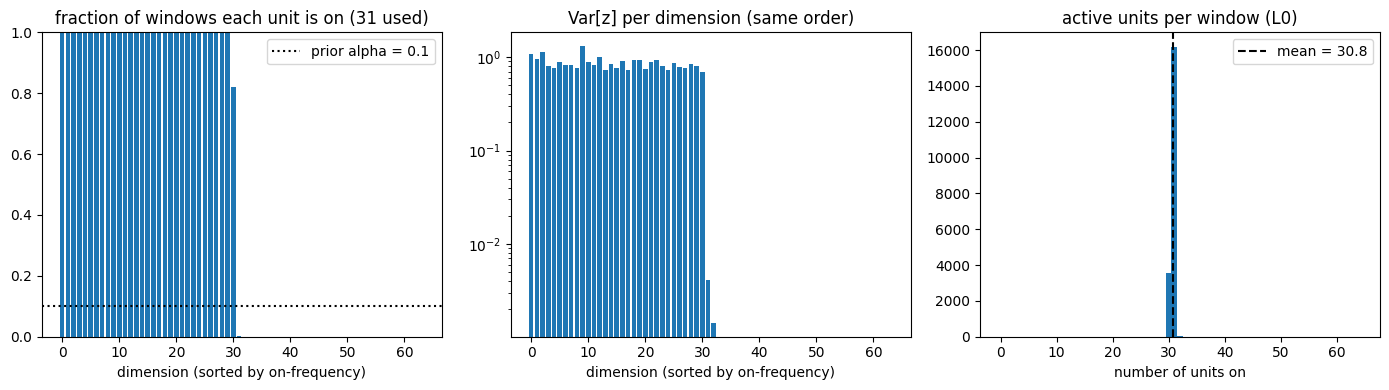

In [14]:
plot_sparse_latent_usage(val_z, val_gamma, alpha=model.alpha)

# See how well it reconstructs

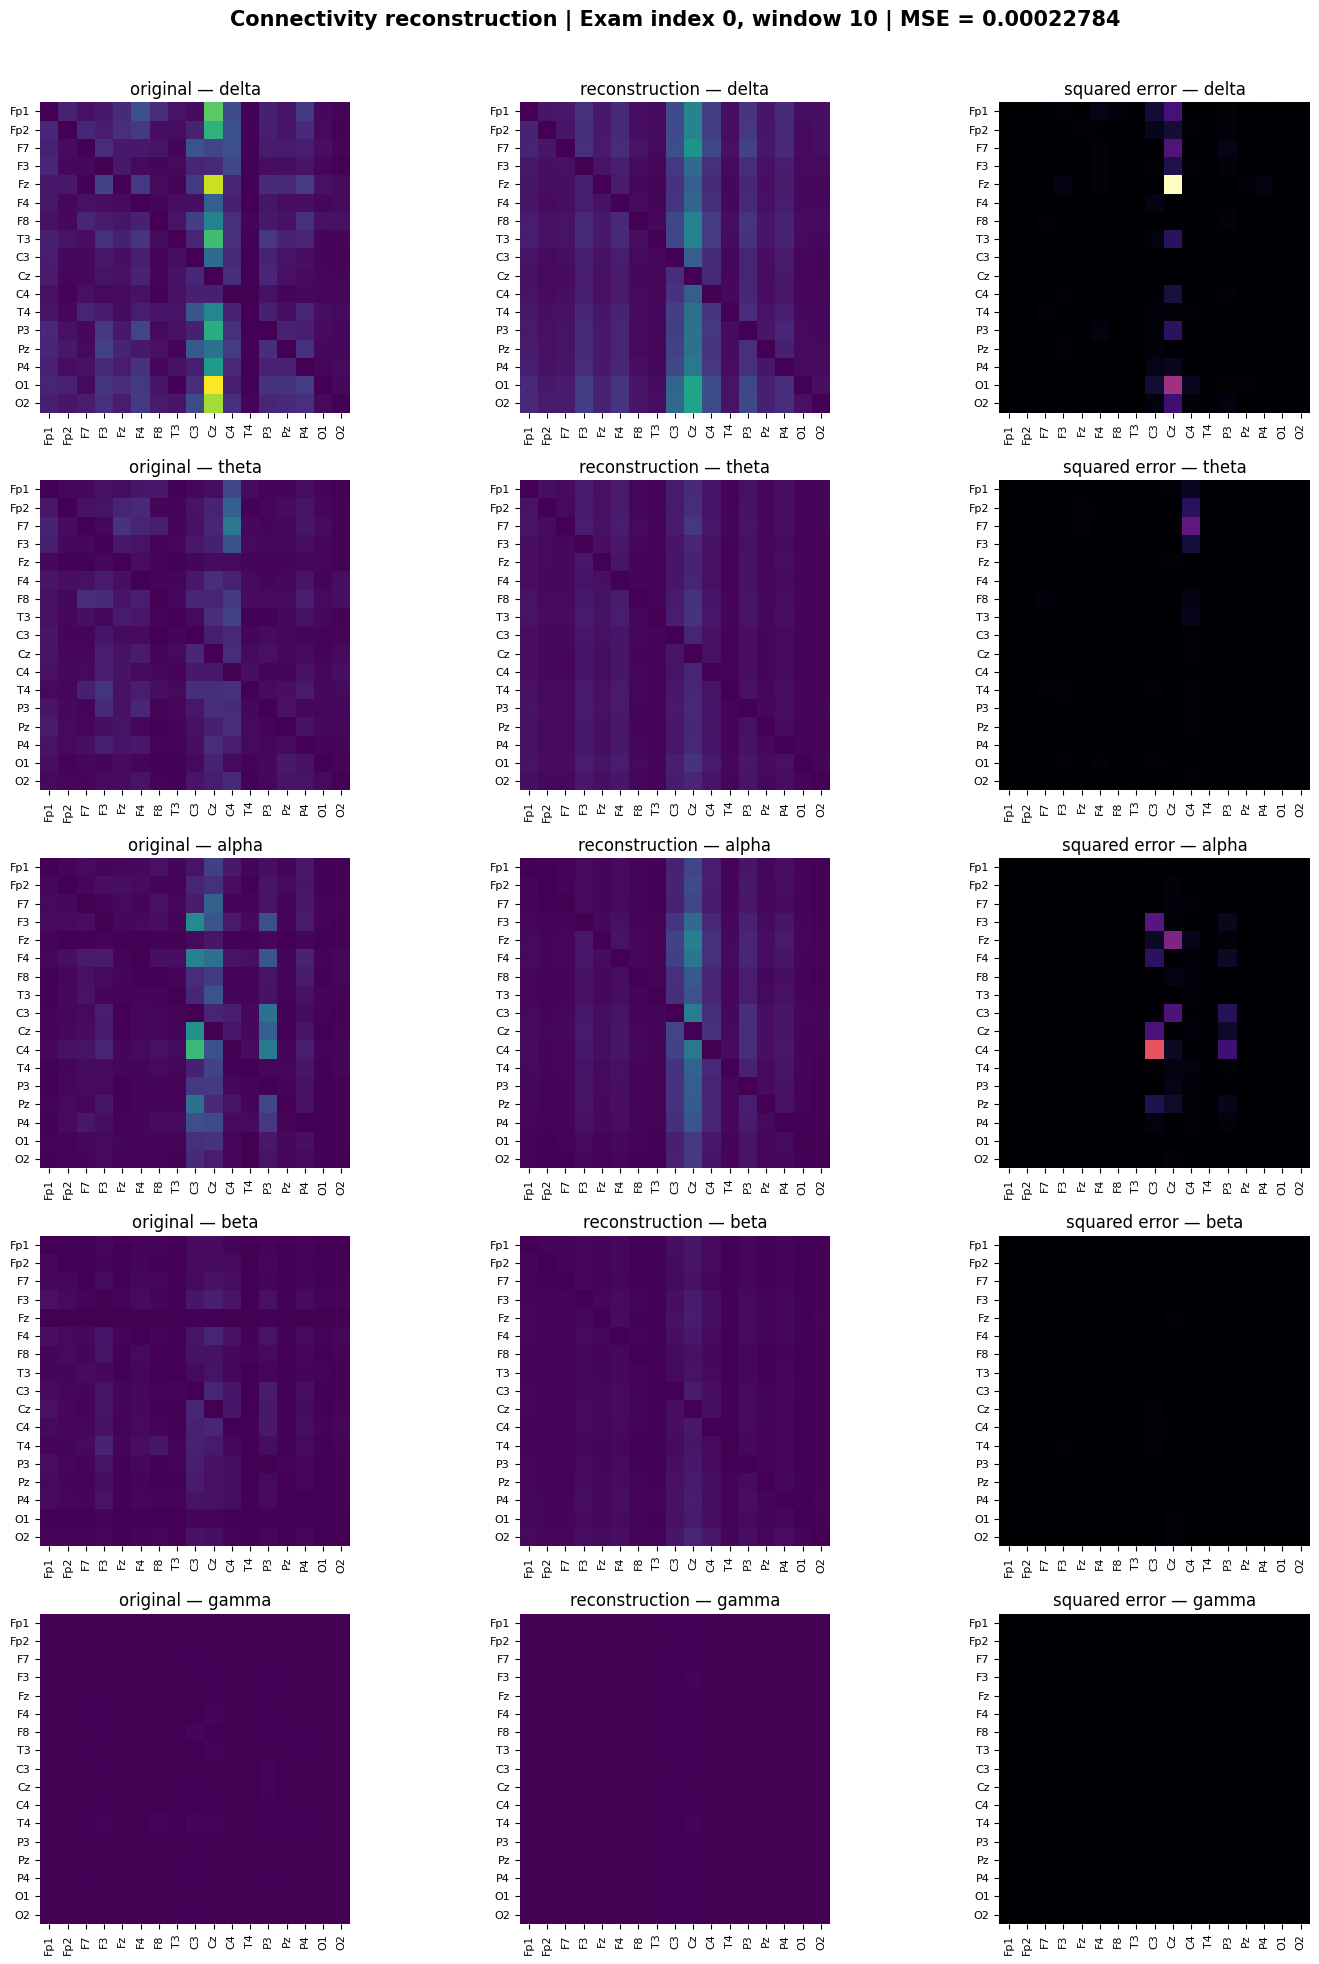

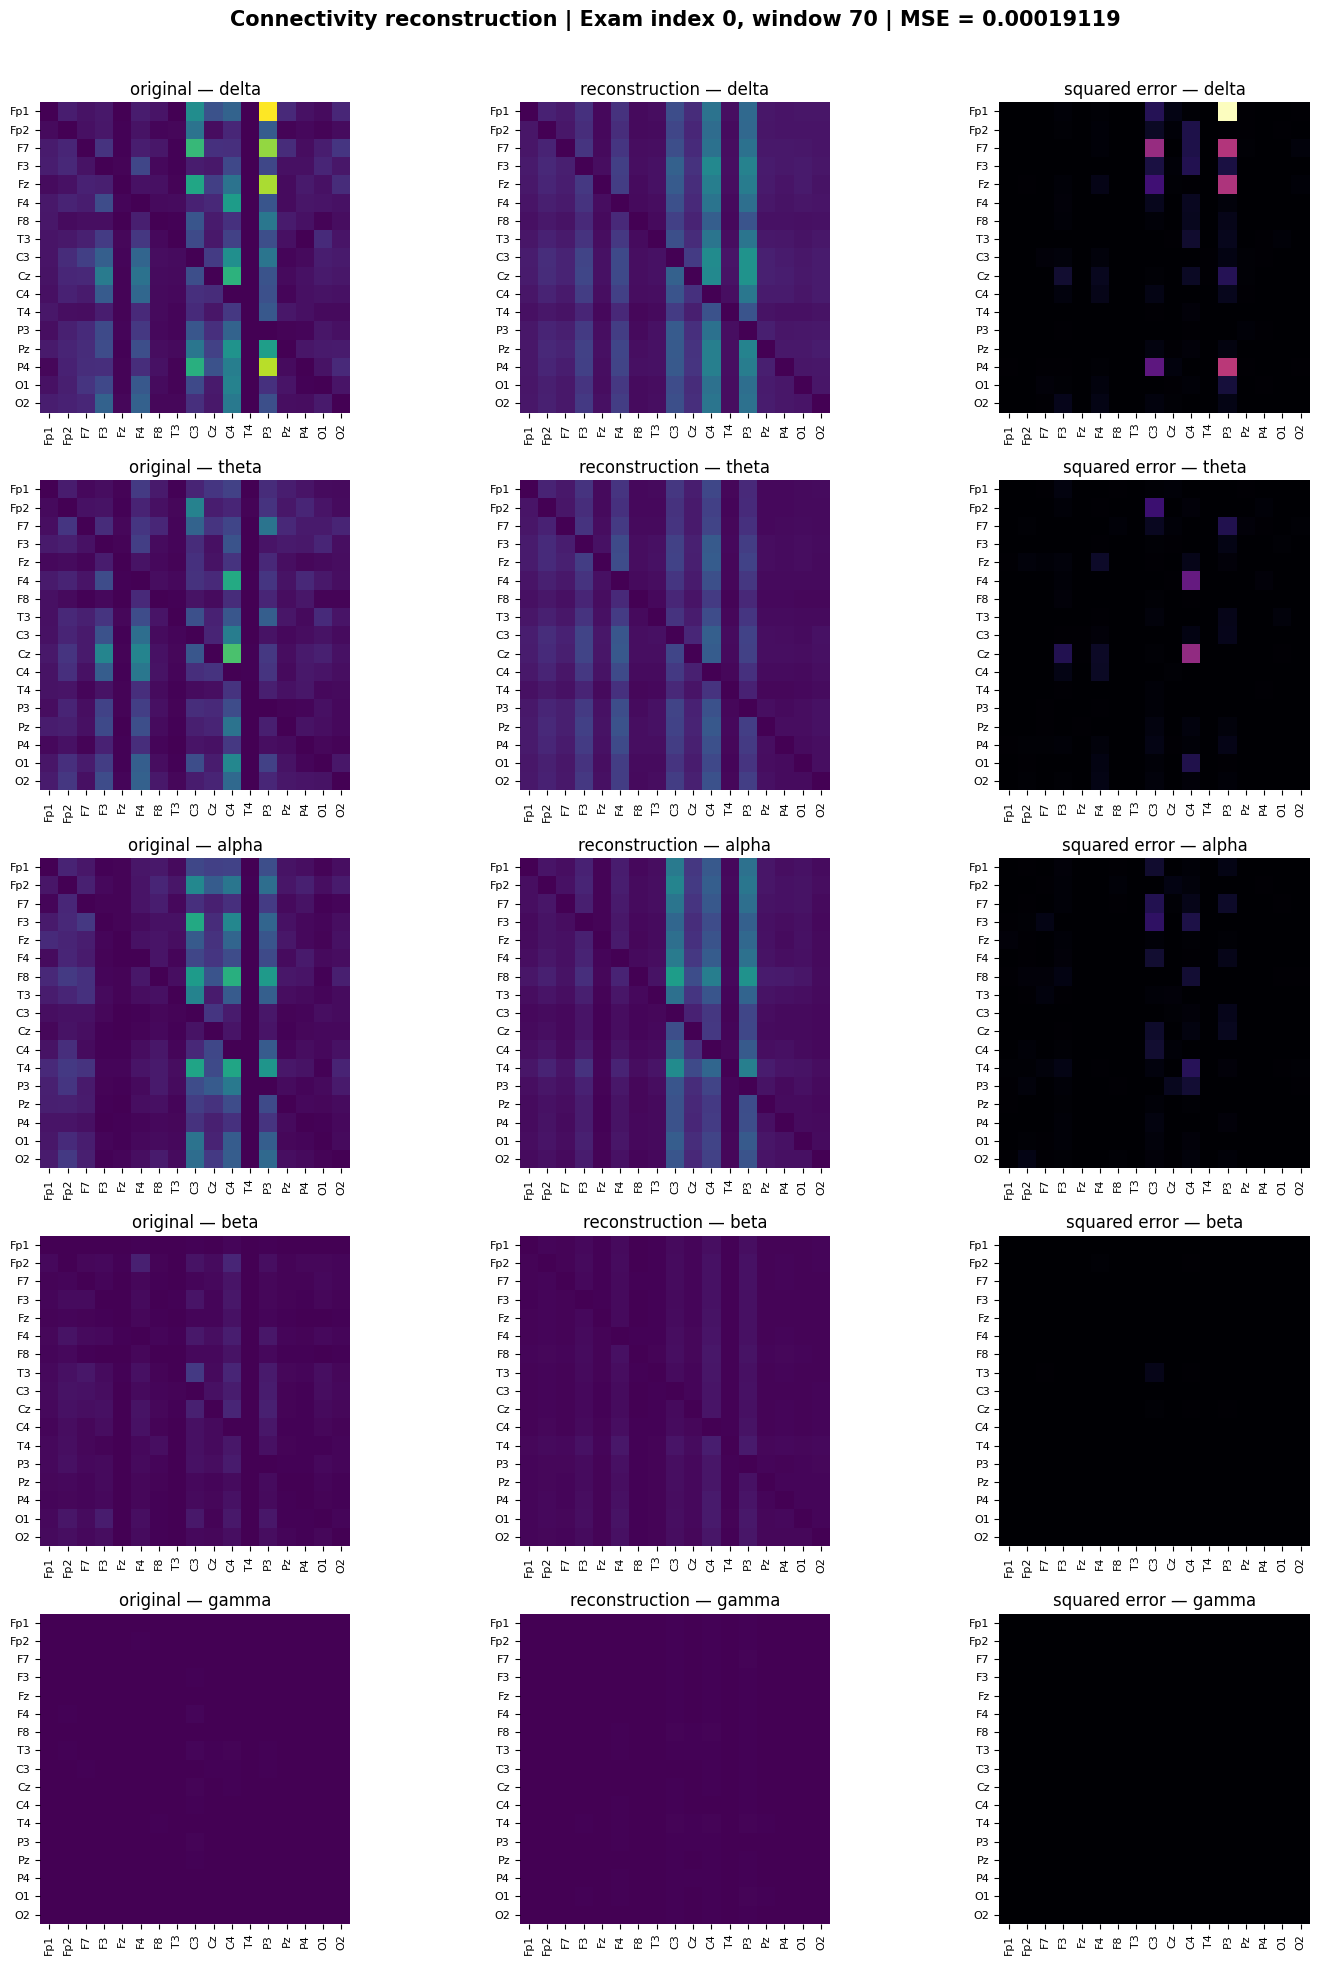

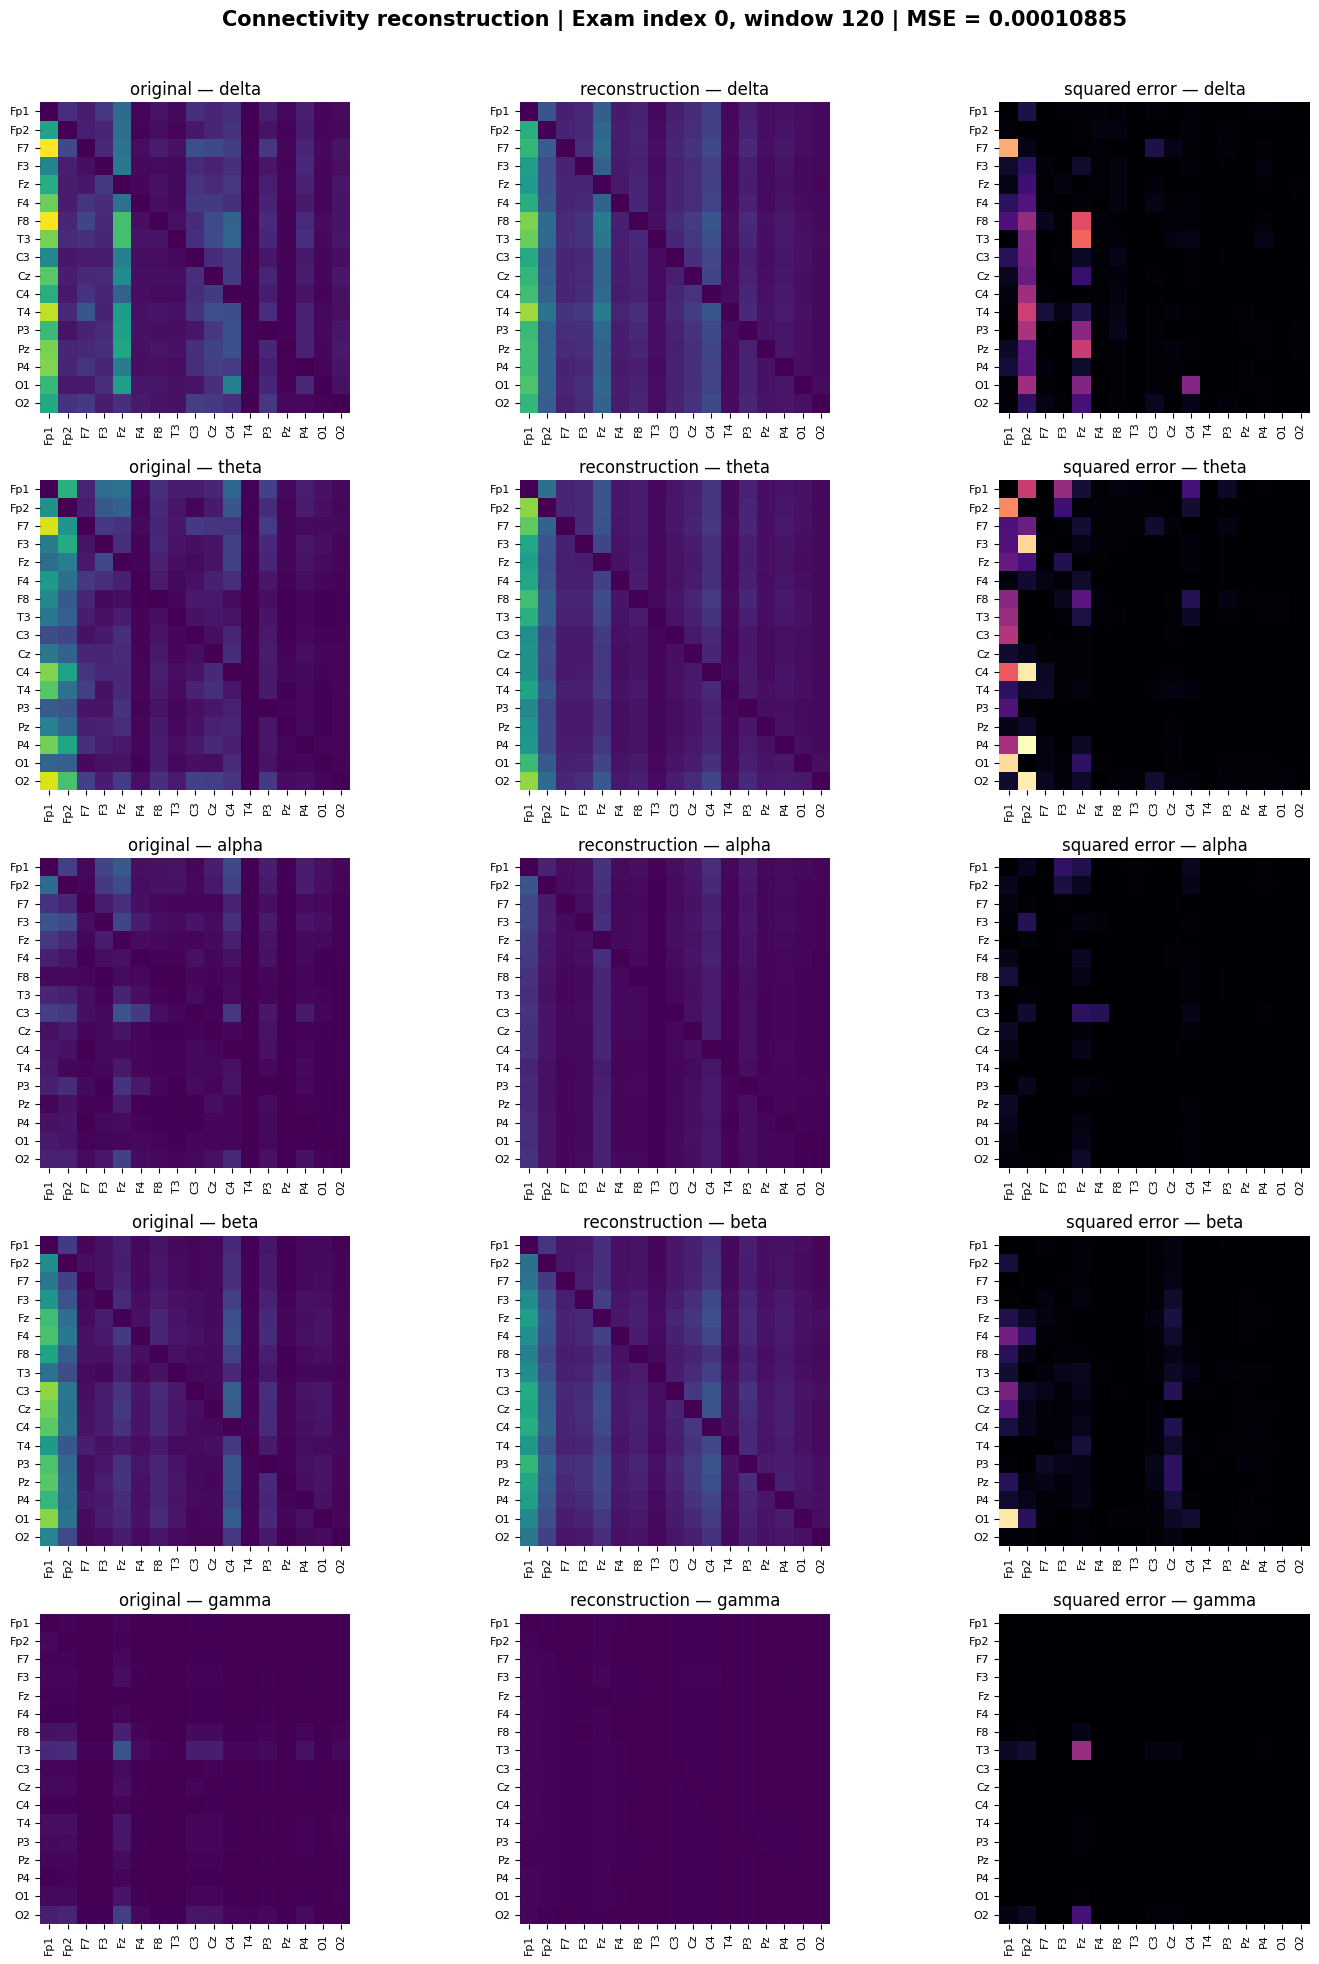

In [15]:
plot_reconstructions(model, val_loader, device, exam_idx=0, window_indices=(10, 70, 120))

# How does the latent space look?

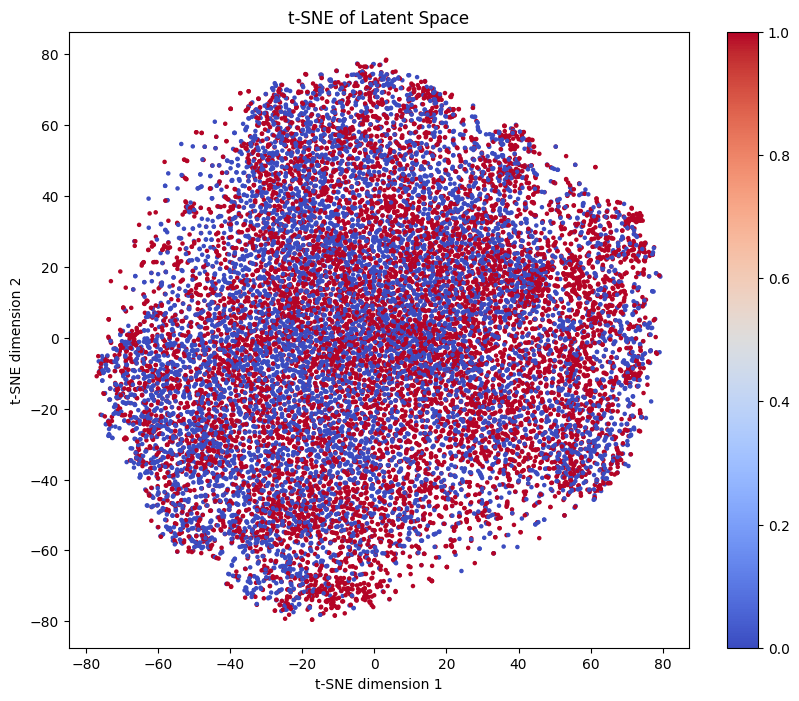

In [16]:
g = plot_tsne(val_z, val_y)
g.show()

# Test out the generative skill

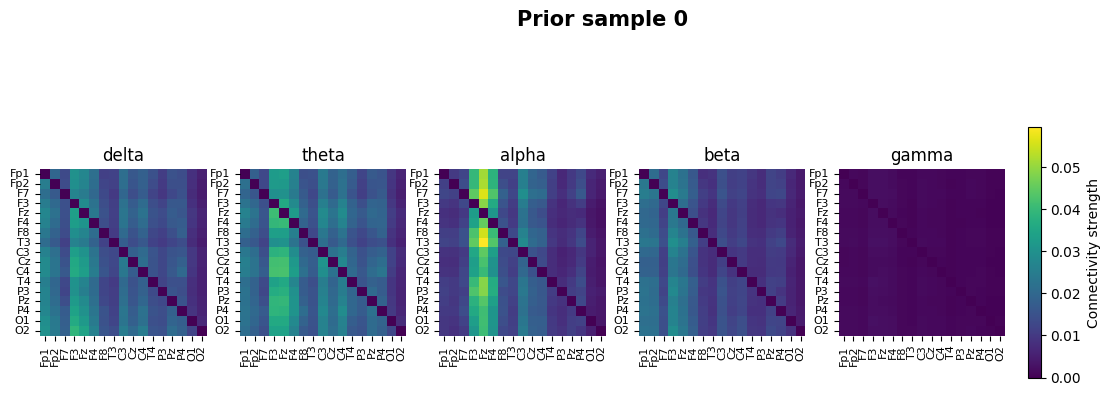

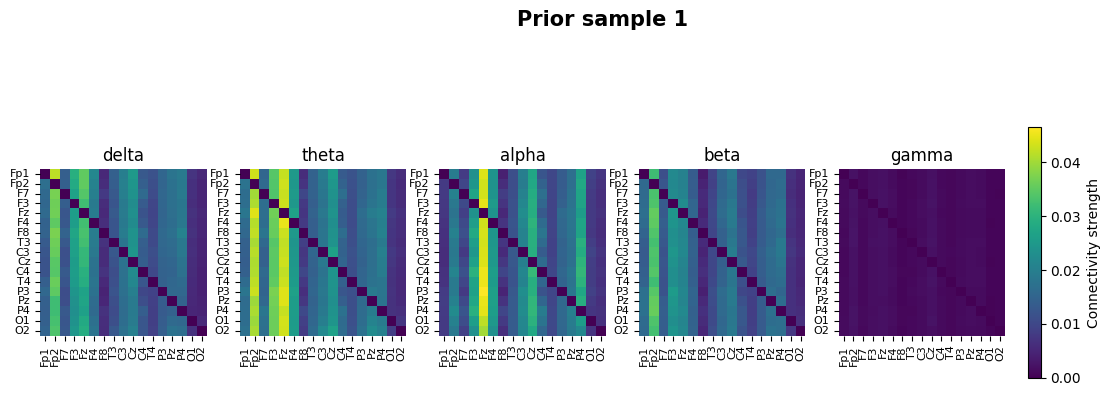

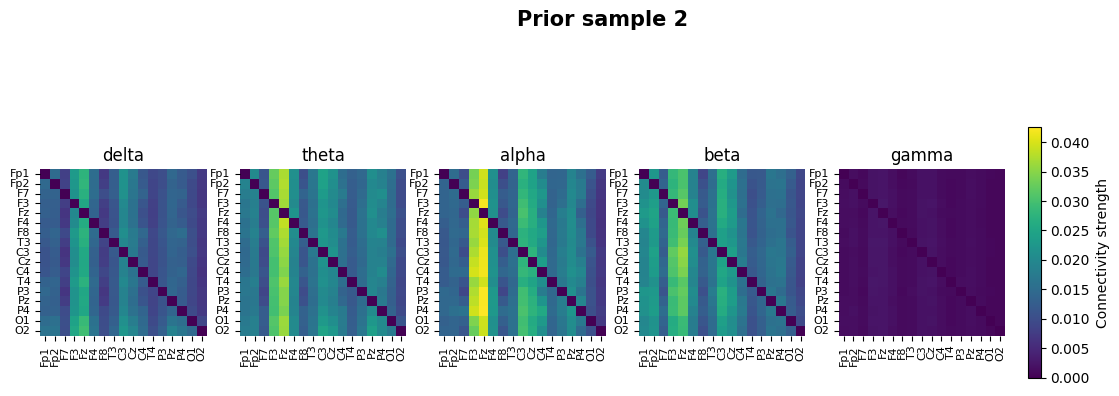

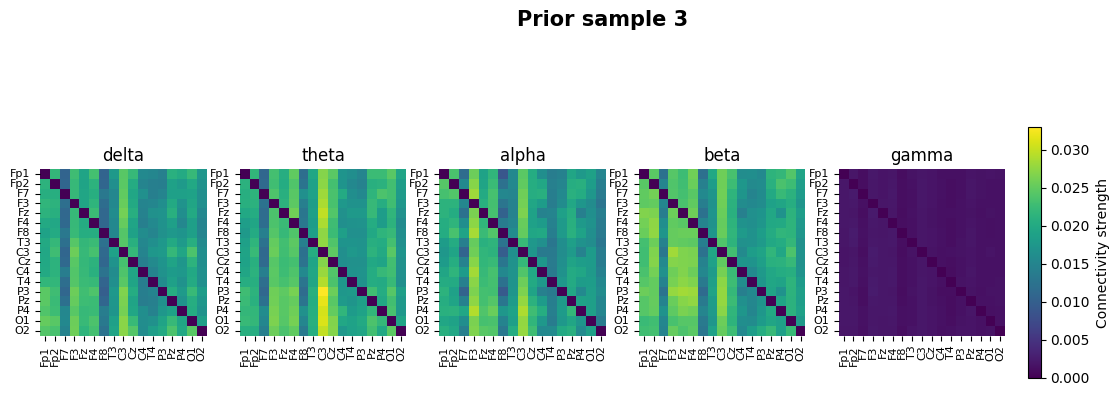

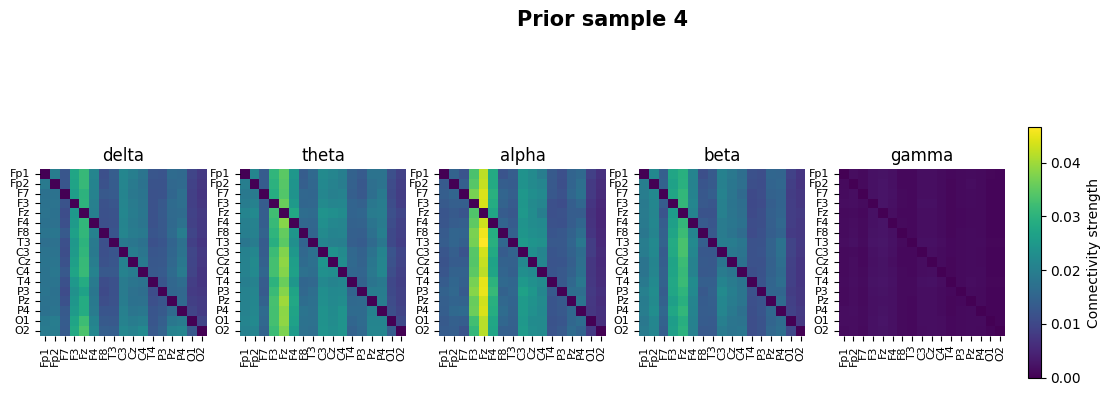

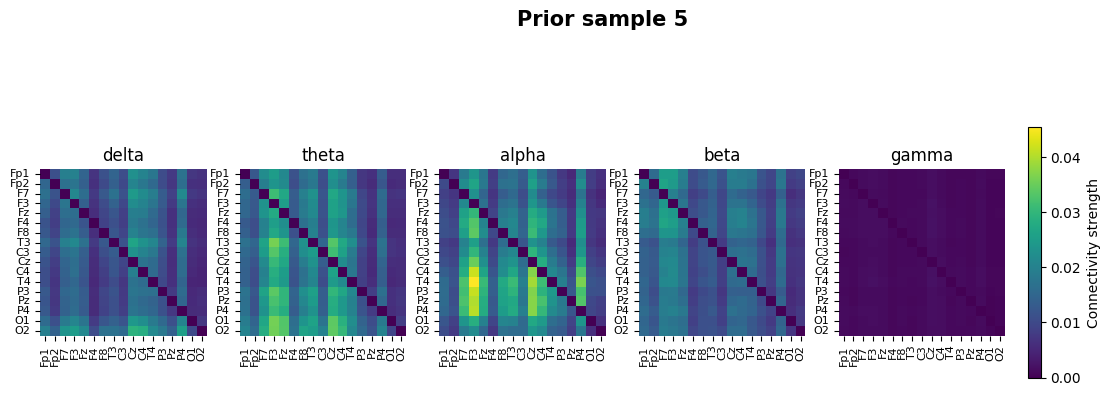

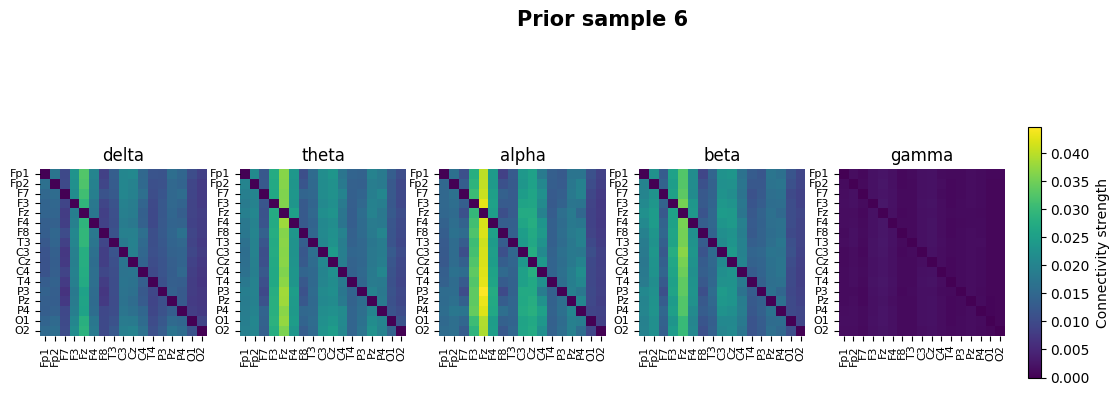

In [17]:
sample_cond = next(iter(val_loader))[2][:7].to(device)  # grab 7 real (age, sex) pairs
plot_prior_samples(model, device, num_samples=7, cond=sample_cond)